In [1]:
import cupy as cp
import cudf

# Availability vector
Josh: There should be 200 alternatives + 1 outside good. The outside good is always available. We'll make a slight change to how the other alternatives appear in the data. Their availability can be governed by independent binomial distributions with 50% probability. For each individual, 200 draws from a binomial distribution will correspond to the availability of the 200 alternatives. The key here is we want widely varying choice sets. Some users might be choosing between 3 options whereas others are choosing between 190 options.

In [372]:
# TODO: source these from the YAML file
n = 200

We will use the Beta distribution that will give us the probability of selecting or not an alternative. We will then use it to tune the `p` parameter of the binomial distribution.

With `a` parameter equal to `2` and the `b` parameter set to `4` -- we get the below shape for the probabilities.

array([[<Axes: title={'center': 'dist'}>]], dtype=object)

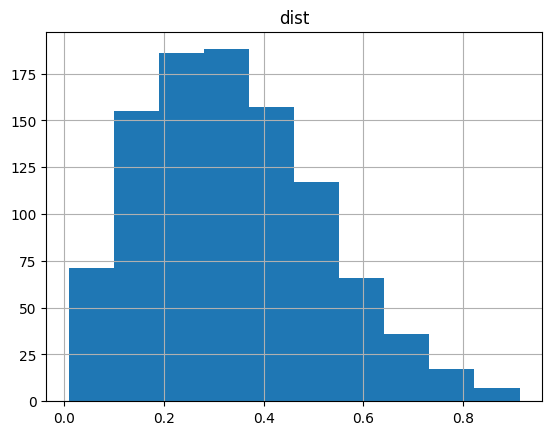

In [366]:
cudf.DataFrame({'dist': cp.random.beta(2,4, size=1000)}).to_pandas().hist()

Using the above defined parameters, we achieve the below distribution of the number of considered alternatives.

(array([[<Axes: title={'center': 'cnts'}>]], dtype=object),
 array([[<Axes: title={'center': 'cnts'}>]], dtype=object))

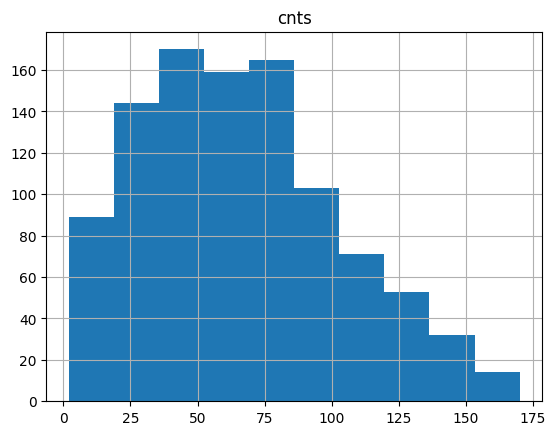

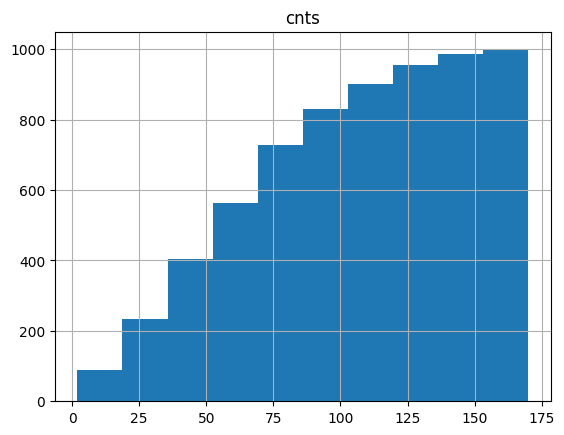

In [375]:
cnts = []
for _ in range(1000):
    # here we're using the beta distribution to determine the probability of being selected as 1
    # this helps with simulating the random number of available alternatives that peaks around 50-75
    # i.e. the median being between 50-75, with a long tail stretching all the way to 200
    avail = cp.random.binomial(1, cp.random.beta(2,4), size=200) 
    cnt = sum(avail)
    cnts.append(cnt)

cnts = cudf.DataFrame({'cnts': cnts})
cnts.to_pandas().hist(cumulative=False), cnts.to_pandas().hist(cumulative=True)

# Data generation (mixed logit)
Each alternative will have 50 features: 45 of which will be homogeneous across alternatives and 5 are heterogeneous and drawn from normal distribution.

$$
\begin{array}{rcl}
V_{1} & = & \beta_{0} * X_{0}^{1} + \ldots + \beta_{45} * X_{45}^{1} + \beta_{46}^{(\mu_{46}, \sigma_{46})} * X_{46}^{1} + \ldots \\
V_{2} & = & \beta_{0} * X_{0}^{2} + \ldots + \beta_{45} * X_{45}^{2} + \beta_{46}^{(\mu_{46}, \sigma_{46})} * X_{46}^{2} + \ldots \\
& \vdots & \\
V_{200} & = & \beta_{0} * X_{0}^{200} + \ldots + \beta_{45} * X_{45}^{200} + \beta_{46}^{(\mu_{46}, \sigma_{46})} * X_{46}^{200} + \ldots \\
\end{array}
$$

The features can be understood as e.g. price, time to wait, time to ride etc.

Also note that the coefficients $\beta_{46 - 50}$ are randomly distributed following normal distribution with their own $\mu$ and $\sigma$ parameters defining the distribution.

Each feature below is standardized to follow normal distribution i.e. $\mu = 0$ and $\sigma = 1$.

In [421]:
alternatives = cp.random.standard_normal(size=(n,50))

Since we have 45 homogenous coefficients, and 5 coefficients that draw from normal, in total we will have 55 coefficients to estimate: 45 homogeneous + 5 means $\mu$ and 5 standard deviations $\sigma$.

In [422]:
coefficients = cp.random.standard_normal(size=45)
coefficients_random = cp.random.standard_normal(size=(5,2))
coefficients_random

array([[-0.15840322, -0.26356999],
       [-1.39608656, -0.14757695],
       [ 0.10977586, -0.61975837],
       [-0.72375004, -0.14176063],
       [ 0.28554445,  0.07473955]])

Now let's specify the alternative specific constants.

In [441]:
# alternative specific constants, normalize the first one to 0
ASC = cp.random.standard_normal(size=n-1)
ASC = cp.append(cp.array([0.00]), ASC)

The error term is drawn from the Gumbel distribution and is assumed IID and IIA.

In [450]:
# error term
error_term = cp.random.gumbel(0,1, size=200)

Finally, we calculate the utility and determine which alternative is to be chosen based on the list of considered `avail` alternatives.

In [557]:
utility = cp.append(alternatives[:,:45] * coefficients, alternatives[:,45:] * cp.array([cp.random.normal(*e) for e in coefficients_random]), axis=1)
utility = cp.append(utility, cp.reshape(ASC, (n,1)), axis=1)
utility = cp.append(utility, cp.reshape(error_term, (n,1)), axis=1)

avail = cp.random.binomial(1, cp.random.beta(2,4), size=n) 
available_utility = cp.sum(utility, axis=1) * avail

Now we need to add out 'outside' alternative. To calculate this, we will use the following formula

$$
V_{\mathtt{outside}} = \ln\Bigg(\frac{p}{1-p}\sum_i \exp^{V_{i}}\Bigg) \\
$$
where $p$ is the probability of selecting the $\mathtt{outside}$ alternative.


In [516]:
outside_alternative_prob = 0.9
multiplier = outside_alternative_prob / (1-outside_alternative_prob)

In [559]:
all_utilities = cp.append(available_utility, cp.log(multiplier * cp.sum(cp.exp(available_utility) * avail)))
avail = cp.append(avail, 1) # the outside alternative is always available

In [585]:
all_utilities_exp = cp.exp(all_utilities) * avail 
all_utilities_exp_sum = cp.sum(all_utilities_exp)
all_probabilities = all_utilities_exp / all_utilities_exp_sum 
all_probabilities * 100

array([7.41564958e-07, 5.29113178e-08, 0.00000000e+00, 2.17464030e-05,
       0.00000000e+00, 4.06412776e-10, 0.00000000e+00, 2.59986248e-05,
       0.00000000e+00, 0.00000000e+00, 5.42562500e-11, 0.00000000e+00,
       2.29505481e-05, 4.28598676e-06, 1.18606248e-03, 0.00000000e+00,
       0.00000000e+00, 6.67960896e-06, 0.00000000e+00, 1.25015396e-04,
       0.00000000e+00, 8.98867833e-07, 4.02857488e-04, 8.15041790e+00,
       3.20433562e-12, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       4.44405161e-11, 0.00000000e+00, 1.19099439e-09, 1.87397955e-05,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.74245704e-05,
       0.00000000e+00, 5.03993341e-07, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       2.03930377e-10, 5.62439971e-04, 0.00000000e+00, 5.94533592e-02,
       0.00000000e+00, 1.85337115e-10, 0.00000000e+00, 0.00000000e+00,
       7.40246540e-08, 0.00000000e+00, 2.74520762e-04, 4.63987298e-08,
      

In [610]:
choice = cp.random.choice(n+1, p=all_probabilities , size=1)
choice

array([23], dtype=int64)

# Nested

Probability of picking an alternative $i$ within nest $s$
$$
P_i^S = \frac{\exp^{V_i / \lambda_S}}{\sum_{j\in S}\exp^{V_j / \lambda_S}}
$$

Probability of picking up nest $s$
$$
P^S = \frac{\lambda_S\sum_{i\in S}\exp^{V_i / \lambda_S}}{\sum_{s^\prime}\lambda_{S^\prime}\sum_{j\in {S^\prime}}\exp^{V_j / \lambda_{S^\prime}}}
$$

Unconditional probability of selecting an alternative $i$
$$
P_i = P^S * P_i^S
$$

In [263]:
utilities_list = [1, 1, 1] # car, red bus, blue bus
nest_coeff = [1, 0.1]   # no correlation

sum_exp_buses = sum([cp.exp(u / nest_coeff[1]) for u in utilities[1:]])
sum_exp_car   = cp.exp(utilities[0] / nest_coeff[0])
sum_exp_buses, sum_exp_car

(array(44052.93158961), array(2.71828183))

In [264]:
V_bus = nest_coeff[1] * cp.log(sum([cp.exp(u / nest_coeff[1]) for u in utilities[1:]]))
V_car = utilities[0]

In [265]:
# exp_bus_nest = 1 / nest_coeff[1] * sum_exp_buses
# exp_car_nest = 1 / nest_coeff[0] * sum_exp_car

sum_exp = cp.exp(V_bus) + cp.exp(utilities[0])

p_bus = cp.exp(V_bus) / sum_exp
p_car = cp.exp(V_car) / sum_exp

p_bus_red  = p_bus_red_nest  * p_bus
p_bus_blue = p_bus_blue_nest * p_bus

p_bus_red, p_bus_blue, p_car, p_bus
# sum_exp


(array(0.25866087), array(0.25866087), array(0.48267826), array(0.51732174))

In [266]:
# V_bus = 1 / nest_coeff[1] * cp.log(sum([cp.exp(u * nest_coeff[1]) for u in utilities_list[1:]]))
V_bus

array(1.06931472)

Trying to vectorize stuff.

In [732]:
n_alternatives = 3
n_attributes = 3
n_decision_makers = 50 

alternatives = cp.array([
    [
        [2,2,2],
        [2,2,2],
        [2,2,2]
    ]
] * n_decision_makers)

coefficients = cp.array([1/6, 1/6, 1/6])
utilities = cp.matmul(alternatives, coefficients)

In [733]:
nest_membership = cp.array([
    [1,0], # car
    [0,1], # bus red
    [0,1]  # bus blue
])
nest_membership_exploded = cp.array([nest_membership.T] * n_decision_makers)
nest_coeff = cp.array([[1, 0.1]])

In [735]:
utilities_within_nest = cp.transpose(utilities * cp.transpose(nest_membership_exploded, axes=(1,0,2)), axes=(1,0,2))
nest_utilities_interim = (nest_membership_exploded * cp.exp(cp.transpose(utilities_within_nest, axes=(0,1,2)) / nest_coeff.T))
nest_utilities = nest_coeff * cp.log(cp.sum(cp.transpose(nest_utilities_interim, axes=(0,2,1)), axis=1))

In [736]:
p_nests = cp.exp(nest_utilities) / sum_exp
utility_exp = cp.exp(utilities_within_nest) * nest_membership.T
sum_exp_within_nests = cp.sum(cp.transpose(utility_exp, axes=(0,2,1)), axis=1)

In [741]:
sum_exp_within_nests = cp.transpose(cp.transpose(utility_exp, axes=(2,1,0)) / sum_exp_within_nests.T, axes=(2,1,0))

In [742]:
p_alternatives = cp.sum(cp.transpose(cp.transpose(sum_exp_within_nests, axes=(2,0,1)) * p_nests, axes=(1,0,2)), axis=2)
p_alternatives

array([[0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.48267826, 0.25866087, 0.25866087],
       [0.

In [364]:
cp.bincount(cp.random.choice(cp.arange(n_alternatives), 10000, p=p_alternatives))

array([4859, 2542, 2599])